In [93]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

"""import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))"""

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Speech Emotion Recognition on RAVDESS
**Goal:** classify 8 emotions (neutral, calm, happy, sad, angry, fearful, disgust, surprised) from short speech clips, evaluated on speakers the model has never seen.

**Approach:**
1. Handcrafted acoustic features (pitch, loudness, voice quality, spectral, MFCC)
2. Pretrained WavLM embeddings
3. Fusion of both

This cell is the Kaggle starter: it imports numpy and pandas and sets up `kagglehub` for dataset access.

In [94]:
import glob, os
import pandas as pd

ROOT = "/kaggle/input/datasets/uwrfkaggler/ravdess-emotional-speech-audio"

emotions={1:"neutral",2:"calm",3:"happy",4:"sad",5:"angry",6:"fearful",7:"disgust",8:"surprised"}

rows=[]
for path in glob.glob(f"{ROOT}/Actor_*/*.wav"): 
    parts=os.path.basename(path)[:-4].split("-")
    rows.append({"path": path,"emotion": emotions[int(parts[2])],"actor": int(parts[6])})

df=pd.DataFrame(rows)
df.head()

,path,emotion,actor
0,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,surprised,2
1,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,neutral,2
2,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,disgust,2
3,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,disgust,2
4,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,neutral,2


## 1. Dataset
RAVDESS filenames encode metadata as dash-separated fields. The 3rd field is the emotion code and the 7th is the actor ID. This cell scans all `Actor_*` folders and builds a dataframe with one row per clip: `path`, `emotion` (mapped from the code) and `actor`.
Preview of the dataframe to confirm paths, labels, actor IDs and loaded audio arrays.

In [95]:
import librosa

def load(path):
    y,sr=librosa.load(path,sr=16000)
    y,_=librosa.effects.trim(y,top_db=30)
    return y

df["audio"]=df["path"].apply(load)

### Audio loading and trimming
Each clip is loaded at 16 kHz mono, which is the sampling rate WavLM expects. Leading and trailing silence is trimmed (`top_db=30`) so that clip length and energy statistics reflect the speech itself, not the recording padding. The waveforms are stored in the `audio` column.

In [96]:
df.head()

,path,emotion,actor,audio
0,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,surprised,2,"[2.6280386e-06, 2.730233e-05, 1.819771e-05, 1...."
1,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,neutral,2,"[6.4194655e-06, 5.372975e-06, 7.2340945e-06, 4..."
2,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,disgust,2,"[-0.0008318698, 0.00027046184, 0.0007171357, 0..."
3,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,disgust,2,"[-3.5293415e-06, 3.6140132e-06, -9.80499e-06, ..."
4,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,neutral,2,"[7.80095e-05, 6.49316e-05, 2.7116545e-05, 9.52..."


### Waveform inspection
Plots the waveform of one clip as a sanity check that loading and trimming worked.

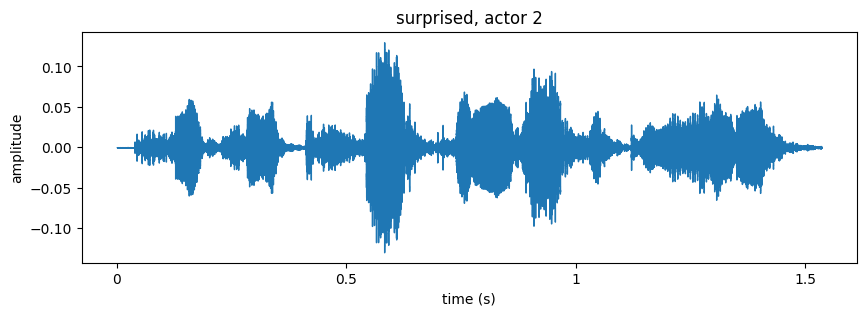

In [97]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 3))
demo=df["audio"][0]
sr=16000
librosa.display.waveshow(demo,sr=sr)
plt.title(f'{df["emotion"][0]}, actor {df["actor"][0]}')
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.show()

In [98]:
pip install praat-parselmouth

Note: you may need to restart the kernel to use updated packages.


## 2. Handcrafted feature extraction
Installs `praat-parselmouth`, a Python interface to Praat. It is used for pitch, intensity, jitter, shimmer, HNR and formants, which librosa does not provide in the same form.

### Pitch (f0) contour
Estimates the fundamental frequency with Praat between 70 and 550 Hz, which covers male and female speech. Only voiced frames (f0 > 0) are kept. Summary statistics are computed from this contour in the next cells.

In [99]:
import parselmouth
from parselmouth.praat import call

def f0(y):
    sr=16000
    y=y["audio"]
    snd=parselmouth.Sound(y.astype(np.float64),sampling_frequency=sr)
    f0=snd.to_pitch(pitch_floor=70,pitch_ceiling=550).selected_array["frequency"]
    return f0[f0>0]
df["f0"]=df.apply(f0,axis=1)

In [100]:
df.head()

,path,emotion,actor,audio,f0
0,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,surprised,2,"[2.6280386e-06, 2.730233e-05, 1.819771e-05, 1....","[261.27169483466446, 257.3206766181644, 262.54..."
1,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,neutral,2,"[6.4194655e-06, 5.372975e-06, 7.2340945e-06, 4...","[308.9783700265456, 308.62331012654306, 309.62..."
2,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,disgust,2,"[-0.0008318698, 0.00027046184, 0.0007171357, 0...","[250.08643254564726, 255.8351639639392, 259.58..."
3,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,disgust,2,"[-3.5293415e-06, 3.6140132e-06, -9.80499e-06, ...","[269.63737302793464, 253.14986096537905, 237.0..."
4,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,neutral,2,"[7.80095e-05, 6.49316e-05, 2.7116545e-05, 9.52...","[286.28732333418156, 275.30220264235584, 262.3..."


Playback of one clip for a quick listening check.

In [101]:
from IPython.display import Audio
Audio(df["audio"][0],rate=16000)

## 3. Speaker-independent split
Uses `GroupShuffleSplit` on `actor` with a 75/25 split, so every actor is entirely in train or entirely in test. A random clip-level split would put the same speaker, voice and sentences in both sets and give inflated scores because the model could partly memorize speakers.

In [102]:
from sklearn.model_selection import GroupShuffleSplit

gss=GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
tr,te=next(gss.split(df, groups=df["actor"]))
x_train,x_test=df.iloc[tr],df.iloc[te]
y_train=x_train["emotion"]
y_test=x_test["emotion"]

### Class balance
Pie chart of the training label distribution. Neutral has about half as many clips as the other emotions in RAVDESS, which is why class weights and macro-averaged metrics are used later.

<Axes: ylabel='proportion'>

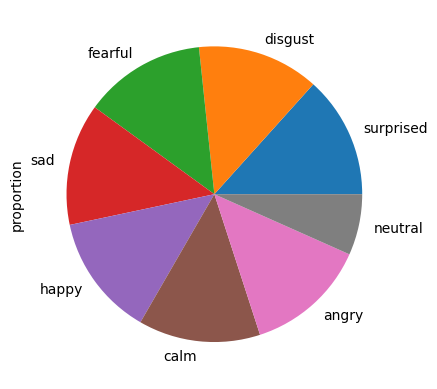

In [103]:
freq=y_train.value_counts(normalize=True)
freq.plot(kind="pie")

In [104]:
x_train=x_train.drop("emotion", axis=1)
x_test=x_test.drop("emotion", axis=1)

### Pitch statistics
Mean, standard deviation and range of f0 per clip. Clips with fewer than 10 voiced frames get NaN for mean and std. Pitch level and variability are strong cues for arousal (angry and happy tend to be high and variable, sad tends to be low and flat).

In [105]:
import warnings
warnings.filterwarnings("ignore")

for x in (x_train,x_test):
    f0=x["f0"]
    x["f0_mean"]=f0.apply(lambda a:a.mean() if len(a)>10 else np.nan)
    x["f0_std"]=f0.apply(lambda a:a.std() if len(a)>10 else np.nan)
    x["pitch_range"]=f0.apply(lambda a:a.max()-a.min())

In [106]:
x.head(2)

,path,actor,audio,f0,f0_mean,f0_std,pitch_range
60,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,17,"[-5.51193e-05, -3.6885984e-05, 2.1283242e-05, ...","[140.0234615730577, 135.93230938603384, 133.36...",119.284164,15.907454,60.638308
61,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,17,"[-9.613538e-05, -9.991041e-05, -8.617541e-05, ...","[204.19820582800077, 233.99121869170148, 269.0...",224.131775,66.000886,390.054316


### Intensity
Function that computes the intensity contour in dB with Praat. It gives a loudness measure over time.

In [107]:
def intensity(y):
    sr=16000
    snd=parselmouth.Sound(y.astype(np.float64),sampling_frequency=sr)
    intensity=snd.to_intensity(minimum_pitch=75).values.flatten()
    return intensity

Intensity summary features: mean (overall loudness), standard deviation and range (loudness dynamics).

In [108]:
for x in (x_train,x_test):
    x["intensity"]=x["audio"].apply(intensity) 
    inten=x["intensity"]
    x["int_mean"]=inten.apply(lambda a:a.mean() if len(a)>10 else np.nan)
    x["int_std"]=inten.apply(lambda a:a.std() if len(a)>10 else np.nan)
    x["int_range"]=inten.apply(lambda a:a.max()-a.min())

### Timbre (MFCC)
Function that computes 30 MFCCs per clip and summarizes each with its mean and standard deviation across time, giving 60 values. MFCCs describe the spectral shape of the voice and are the standard baseline feature for speech emotion.

In [109]:
def timbre_mfccs(y):
    sr=16000
    mfcc=librosa.feature.mfcc(y=y,sr=sr,n_mfcc=30)
    output=np.concatenate([mfcc.mean(axis=1),mfcc.std(axis=1)])
    return output

In [110]:
for x in (x_train,x_test):
    m=np.vstack(x["audio"].apply(timbre_mfccs).values)
    for i in range(m.shape[1]):
        x[f"mfcc_{i}"]=m[:,i]

### Pitch slope
Fits a straight line to the f0 contour and keeps its slope, which captures overall rising or falling intonation. Set to NaN when there are fewer than 10 voiced frames.

In [111]:
x_train["f0_slope"]=x_train["f0"].apply(lambda a:np.polyfit(np.arange(len(a)),a,1)[0] if len(a) > 10 else np.nan)
x_test["f0_slope"]=x_test["f0"].apply(lambda a:np.polyfit(np.arange(len(a)),a,1)[0] if len(a) > 10 else np.nan)

### Loudness and speaking rate
Function returning RMS energy (mean, std, max), clip duration and onset rate. Because RAVDESS actors read the same two sentences, duration is a clean speaking-rate measure. Onset rate (onsets per second) is a rough syllable-rate proxy.

In [112]:
def rms_rate(y,sr=16000):
    rms=librosa.feature.rms(y=y)[0]
    dur=len(y)/sr
    onsets=librosa.onset.onset_detect(y=y,sr=sr,units="time")
    return [rms.mean(),rms.std(),rms.max(),dur,len(onsets)/dur]

In [113]:
cols=["rms_mean","rms_std","rms_max","duration","onset_rate"]
for x in (x_train,x_test):
    m=np.vstack(x["audio"].apply(rms_rate).values)
    for i,c in enumerate(cols):
        x[c]=m[:,i]

### Voice quality
Computes with Praat:
- **Jitter**: cycle-to-cycle pitch instability
- **Shimmer**: cycle-to-cycle amplitude instability
- **HNR**: harmonics-to-noise ratio (breathiness or strain)
- **F1-F3**: mean formants (vocal tract shape)

These help separate emotions with similar arousal, such as angry and happy.

In [114]:
def voice_quality(y):
    sr=16000
    snd=parselmouth.Sound(y.astype(np.float64),sampling_frequency=sr)
    pp=call(snd,"To PointProcess (periodic, cc)",70,550)
    jitter=call(pp,"Get jitter (local)",0,0,0.0001,0.03,1.3)
    shimmer=call([snd,pp],"Get shimmer (local)",0,0,0.0001,0.03,1.3,1.6)
    hnr=call(snd.to_harmonicity(),"Get mean",0,0)
    hms=snd.to_formant_burg(max_number_of_formants=5, maximum_formant=5500)
    t=np.linspace(0.05,snd.duration-0.05,20)
    forms=[np.nanmean([hms.get_value_at_time(k,x) for x in t]) for k in (1,2,3)]
    return [jitter,shimmer,hnr,*forms]

Helper for voiced ratio and pause ratio. It is defined here but not used in the final feature set.

In [115]:
def pause(y,f0):
    duration=len(f0)/sr
    iv=librosa.effects.split(y,top_db=30)
    speech=sum(e-s for s,e in iv)/16000
    return [len(f0)/max(1,dur*100),1-speech/dur] 

### Safe wrapper
Praat's jitter and shimmer calls fail on clips with too few voiced periods. This wrapper returns six NaN values in that case so the extraction loop does not crash. Remaining NaNs are checked later.

In [116]:
def parse_properly(y):
    try:
        return voice_quality(y)
    except:
        return [np.nan]*6

In [117]:
cols=["jitter","shimmer","hnr","f1","f2","f3"]
for x in (x_train,x_test):
    m=np.vstack(x["audio"].apply(parse_properly).values)
    for i,col in enumerate(cols):
        x[col]=m[:,i]

In [118]:
x_train.head()

,path,actor,audio,f0,f0_mean,f0_std,pitch_range,intensity,int_mean,int_std,...,rms_std,rms_max,duration,onset_rate,jitter,shimmer,hnr,f1,f2,f3
0,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,2,"[2.6280386e-06, 2.730233e-05, 1.819771e-05, 1....","[261.27169483466446, 257.3206766181644, 262.54...",295.880276,95.286986,316.411304,"[45.006000567499875, 48.055631975949765, 49.74...",55.680589,6.527153,...,0.007938,0.035942,1.536,7.812500,0.027435,0.130230,8.913758,711.450435,1922.568539,3054.422455
1,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,2,"[6.4194655e-06, 5.372975e-06, 7.2340945e-06, 4...","[308.9783700265456, 308.62331012654306, 309.62...",241.718503,59.826938,212.715430,"[40.51300173642965, 40.8377457491268, 40.66171...",48.005509,7.811164,...,0.005000,0.018424,1.696,11.792453,0.022360,0.121935,10.211250,698.036150,1794.475582,2765.552655
2,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,2,"[-0.0008318698, 0.00027046184, 0.0007171357, 0...","[250.08643254564726, 255.8351639639392, 259.58...",228.622819,57.985450,271.937032,"[49.80566553466399, 55.10534619460685, 58.2296...",51.313366,8.203538,...,0.009243,0.039794,2.080,9.615385,0.032835,0.126295,9.816716,791.364873,1843.647536,2876.826344
3,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,2,"[-3.5293415e-06, 3.6140132e-06, -9.80499e-06, ...","[269.63737302793464, 253.14986096537905, 237.0...",193.716113,48.218453,199.510110,"[33.66212796880702, 35.110597405116465, 36.923...",46.896367,7.319935,...,0.003878,0.014065,1.728,9.259259,0.031563,0.119889,7.890212,705.911715,1792.862800,2815.918599
4,/kaggle/input/datasets/uwrfkaggler/ravdess-emo...,2,"[7.80095e-05, 6.49316e-05, 2.7116545e-05, 9.52...","[286.28732333418156, 275.30220264235584, 262.3...",239.397563,54.650080,280.857903,"[49.05645912480558, 54.74249563651833, 58.1059...",52.017530,7.216393,...,0.007644,0.034711,1.792,6.696429,0.022179,0.106506,11.628335,608.928164,1748.754716,2794.105417


### Spectral brightness and timbre change
- Spectral centroid (mean, std) and rolloff: how bright the sound is
- Spectral tilt (`alpha`): ratio of energy above vs below 1 kHz, higher for harsh or tense speech
- Mean absolute delta of 13 MFCCs: how quickly the timbre changes over time, which static MFCC averages miss

In [119]:
def bright_delta(y,sr=16000):
    S=np.abs(librosa.stft(y))**2
    freqs=librosa.fft_frequencies(sr=sr)
    cent=librosa.feature.spectral_centroid(S=np.sqrt(S),sr=sr)[0]
    roll=librosa.feature.spectral_rolloff(S=np.sqrt(S),sr=sr)[0]
    low=S[freqs<1000].sum()
    high=S[freqs>=1000].sum()
    alpha=10*np.log10((high+1e-10)/(low+1e-10))
    d=librosa.feature.delta(librosa.feature.mfcc(y=y,sr=sr,n_mfcc=13))
    return [cent.mean(),cent.std(),roll.mean(),alpha,*np.abs(d).mean(axis=1)]

In [120]:
bd_cols=["cent_mean","cent_std","roll_mean","alpha"]+[f"dmfcc_{i}" for i in range(13)]
for x in (x_train,x_test):
    m=np.vstack(x["audio"].apply(bright_delta).values)
    for i,col in enumerate(bd_cols):
        x[col]=m[:,i]

In [121]:
x_train=x_train.drop(['path'],axis=1)
x_test=x_test.drop(['path'],axis=1)

In [122]:
x_train=x_train.drop(["f0"],axis=1)
x_test=x_test.drop(["f0"],axis=1)
x_train=x_train.drop(["intensity","audio"],axis=1)
x_test=x_test.drop(["intensity","audio"],axis=1)

### Per-actor normalization
Each feature is z-scored within each actor (subtract the actor's own mean, divide by the actor's own standard deviation). This removes speaker-specific baselines such as average pitch, loudness and formants, so the model focuses on how emotion changes the voice. It uses only each actor's own feature values and never the labels, so there is no label leakage. It does require several clips from the same speaker at prediction time. The actor column is then dropped.

In [123]:
feats=[c for c in x_train.columns if c!="actor"]
for x in (x_train,x_test):
    x[feats]=x.groupby("actor")[feats].transform(lambda s:(s-s.mean())/(s.std()+1e-8))
x_train=x_train.drop(columns=["actor"])
x_test=x_test.drop(columns=["actor"])

In [124]:
len(x_train.columns)

95

In [125]:
print(x_train.isnull().sum().sum())
x_test.isnull().sum().sum()

0


np.int64(0)

In [126]:
x_train.dtypes.value_counts()

float32    60
float64    35
Name: count, dtype: int64

## 5. Models on handcrafted features
Standardizes the features with a `StandardScaler` fitted on the training set only and applied to the test set. This matters for SVC and MLP, which are sensitive to feature scale.

In [127]:
from sklearn.preprocessing import StandardScaler

ss=StandardScaler()
x_train_scaled=ss.fit_transform(x_train)
x_test_scaled=ss.transform(x_test)
print(x_train_scaled.mean(),x_test_scaled.mean())

2.3805951795081328e-18 -2.9495005666176995e-09


### Label encoding
Maps emotions to integers 0-7 in alphabetical order (angry=0, calm=1, disgust=2, fearful=3, happy=4, neutral=5, sad=6, surprised=7). The encoder is fitted on the training labels only, and the printed mapping is used to read confusion matrices.

In [128]:
from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()
y_train=le.fit_transform(y_train)
y_test=le.transform(y_test)

print(dict(zip(le.classes_,le.transform(le.classes_))))

{'angry': np.int64(0), 'calm': np.int64(1), 'disgust': np.int64(2), 'fearful': np.int64(3), 'happy': np.int64(4), 'neutral': np.int64(5), 'sad': np.int64(6), 'surprised': np.int64(7)}


### Model 1: SVC (RBF kernel)
Support vector classifier with default `gamma="scale"` and `C=1` on the scaled handcrafted features. Prints test accuracy.

In [129]:
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
svm=SVC(C=1,gamma="scale",kernel="rbf")
svm.fit(x_train_scaled,y_train)
print(accuracy_score(y_test,svm.predict(x_test_scaled)))

0.5638888888888889


### Model 2: MLP
Small neural network with one hidden layer of 128 units, L2 regularization (`alpha=1e-2`) and early stopping on a 15% validation split. Prints test accuracy.

In [130]:
from sklearn.neural_network import MLPClassifier
mlp=MLPClassifier(hidden_layer_sizes=(128,),alpha=1e-2,learning_rate_init=1e-3,early_stopping=True,validation_fraction=0.15,n_iter_no_change=15,max_iter=500,random_state=42)
mlp.fit(x_train_scaled,y_train)
print(accuracy_score(y_test,mlp.predict(x_test_scaled)))

0.55


### Model 3: Stacking
Combines the MLP and the SVC. A logistic regression with an elastic-net penalty learns how to weigh their outputs. Prints test accuracy.

In [131]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

stack=StackingClassifier(final_estimator=LogisticRegression(penalty="elasticnet",solver="saga",l1_ratio=0.3),estimators=[("mlp",mlp),("svm",svm)])
stack.fit(x_train_scaled,y_train)
print(accuracy_score(y_test,stack.predict(x_test_scaled)))

0.5694444444444444


## 6. Pretrained embeddings (WavLM)
Loads `microsoft/wavlm-base-plus`, a speech model pretrained on tens of thousands of hours of audio. For each clip it extracts the hidden states of all 13 layers and averages them over time, giving a 768-dimensional vector per layer. The result is saved as `wavlm_embeds.npy` so the extraction does not need to be repeated. A GPU makes this much faster.

In [132]:
import torch
from transformers import AutoFeatureExtractor,AutoModel

name="microsoft/wavlm-base-plus"
fe=AutoFeatureExtractor.from_pretrained(name)
model=AutoModel.from_pretrained(name).eval()
dev="cuda" if torch.cuda.is_available() else "cpu"
model.to(dev)

def embed(y):
    inp=fe(y,sampling_rate=16000,return_tensors="pt").to(dev)
    with torch.no_grad():
        hs=model(**inp,output_hidden_states=True).hidden_states
    return torch.stack([h[0].mean(0) for h in hs]).cpu().numpy()   

E=np.stack([embed(y) for y in df["audio"]])   
np.save("wavlm_embeds.npy",E)

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

In [133]:
X_emb=pd.DataFrame(E[:,6,:],index=df.index).add_prefix("emb_")
X_emb=X_emb.groupby(df["actor"]).transform(lambda s:(s-s.mean())/(s.std()+1e-8))

tr_idx,te_idx=x_train.index,x_test.index    
ss=StandardScaler().fit(X_emb.loc[tr_idx])
svm_embed=SVC(C=1,class_weight="balanced").fit(ss.transform(X_emb.loc[tr_idx]),y_train)
print(accuracy_score(y_test,svm_embed.predict(ss.transform(X_emb.loc[te_idx]))))

0.775


### Model 5: Early fusion
Concatenates the 95 handcrafted features with the 768 embedding dimensions and trains one SVC on the combined vector. Prints test accuracy.

In [137]:
tr_idx,te_idx=x_train.index,x_test.index
Ftr=np.hstack([x_train.values,X_emb.loc[tr_idx].values])
Fte=np.hstack([x_test.values,X_emb.loc[te_idx].values])

ss=StandardScaler().fit(Xtr)
svm_final=SVC(C=1,class_weight="balanced").fit(ss.transform(Ftr),y_train)
print(accuracy_score(y_test,svm_final.predict(ss.transform(Fte))))

0.7888888888888889


### Results table
Compares the handcrafted models, the WavLM embedding model, early fusion (feature concatenation) and late fusion (weighted average of predicted probabilities with weights 0.5 / 0.25 / 0.25, fixed before testing, not tuned on the test set).

In [139]:
from sklearn.metrics import accuracy_score,f1_score,precision_score,recall_score

def scores(y_true,y_pred):
    return {"Accuracy":accuracy_score(y_true,y_pred),
            "F1 (macro)":f1_score(y_true,y_pred,average="macro"),
            "Precision (macro)":precision_score(y_true,y_pred,average="macro",zero_division=0),
            "Recall (macro)":recall_score(y_true,y_pred,average="macro",zero_division=0)}

In [140]:
preds={
 "Handcrafted | SVC":svm.predict(x_test_scaled),
 "Handcrafted | MLP":mlp.predict(x_test_scaled),
 "Handcrafted | Stacking (MLP+SVC)":stack.predict(x_test_scaled),
 "WavLM embeddings | SVC":svm_embed.predict(Ete),
 "Early fusion (handcrafted+WavLM) | SVC":svm_final.predict(Fte)}

table=pd.DataFrame({k:scores(y_test,v) for k,v in preds.items()}).T.round(4)
table.index.name="Model"
table

,Accuracy,F1 (macro),Precision (macro),Recall (macro)
Model,,,,
Handcrafted | SVC,0.5639,0.5534,0.5602,0.5547
Handcrafted | MLP,0.5500,0.5372,0.5369,0.5391
Handcrafted | Stacking (MLP+SVC),0.5694,0.5544,0.5562,0.5599
WavLM embeddings | SVC,0.7750,0.7829,0.7987,0.7786
Early fusion (handcrafted+WavLM) | SVC,0.7889,0.7938,0.8116,0.7891


### Confusion matrix
Row-normalized confusion matrix for the best model on the held-out test actors. Each row is a true emotion and each column a predicted emotion, so the diagonal shows per-emotion recall. Off-diagonal cells show which emotions get mixed up. The figure is saved to `results/confusion_matrix.png`.

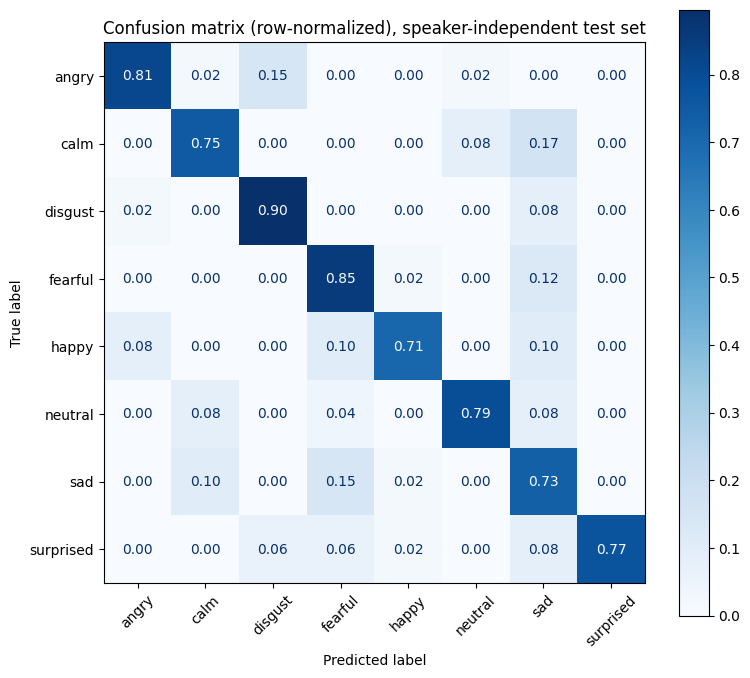

In [141]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

os.makedirs("results",exist_ok=True)

pred=svm_final.predict(ss.transform(Xte))  

fig,ax=plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=le.classes_,normalize="true",xticks_rotation=45,cmap="Blues",values_format=".2f",ax=ax)
ax.set_title("Confusion matrix (row-normalized), speaker-independent test set")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png",dpi=150,bbox_inches="tight")
plt.show()